# Example model training: ΔEdecomp random forest

This walks through how the paper's models are built from the released dataset:
1. the data and how it was cleaned;
2. the grouped train/test split, and why rows are never split at random;
3. feature selection inside each fold;
4. cross-validation and parity plots;
5. fitting and saving the final model.

The held-out test set is never touched here.

In [1]:
%matplotlib inline
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
# Folder holding the data release (Li/, Na/, ..., models/). Set ION_INSERTION_MODELING_DATA to use another place.
DATA = Path(os.environ.get("ION_INSERTION_MODELING_DATA", "../release"))

In [2]:
from ion_insertion_modeling.model_building import (load_dataset, cross_validate, fit_final, rank_features,
                                                   interpretable_ranking, interpretable_walk)
from ion_insertion_modeling.model_building.plots import parity_from_cv
from ion_insertion_modeling.featurizers import FEATURE_SETS

ds = load_dataset("Li", root=DATA)
ds.summary()

{'ion': 'Li',
 'electrodes': 2238,
 'training_electrodes': 2011,
 'test_electrodes': 227,
 'transitions': 2741,
 'unscored_finals': 5,
 'features': 432}

## 1. Data and cleaning

Materials Project InsertionElectrode electrodes with Li as the working ion and O-containing frameworks. Each
electrode's initial (reference) material is its lowest-Edecomp material. Every other material of the electrode gives
one transition (initial → (de)lithiated), with target ΔEdecomp = Edecomp(final) − Edecomp(initial) in eV/atom on
the rebuilt MP2020 GGA/GGA+U hull.

Removed before the split was fixed:

In [3]:
import json
log = json.loads((ds.root / "cleaning_log.json").read_text())
print("electrodes in the MP database:", log["ingest"]["n_batteries"], "| materials:", log["ingest"]["n_materials"])
dropped = pd.read_parquet(ds.root / "batteries_dropped.parquet")
print("\nelectrodes removed:"); print(dropped.reason.value_counts().to_string())
tdrop = pd.read_parquet(ds.root / "transitions_dropped.parquet")
print("\n(de)lithiated materials removed:"); print(tdrop.drop_reason.value_counts().to_string())
print("\nDFT outlier electrode left out:", json.loads((ds.root / "checksums.json").read_text())["outlier_batteries"])

electrodes in the MP database: 2527 | materials: 5583

electrodes removed:
reason
every material above 75 meV/atom                     252
every material above 75 meV/atom, one synthesized     16
framework mismatch                                     4

(de)lithiated materials removed:
drop_reason
magmom_spread           8
nan_edecomp             6
missing_p1              5
no_cation_anion_bond    1

DFT outlier electrode left out: ['mp-787252_Li']


- Electrodes are dropped when every material is more than 75 meV/atom above the hull, or when their materials do not
  share one framework.
- Materials are dropped for implausible Fe/Mn magnetic moments, a missing energy, or no cation–anion bond.
- (De)lithiated materials P1 cannot assign (`missing_p1`) stay in the evaluation: they count as predicted unstable.

40% of (de)lithiated materials are more than 75 meV/atom above the hull


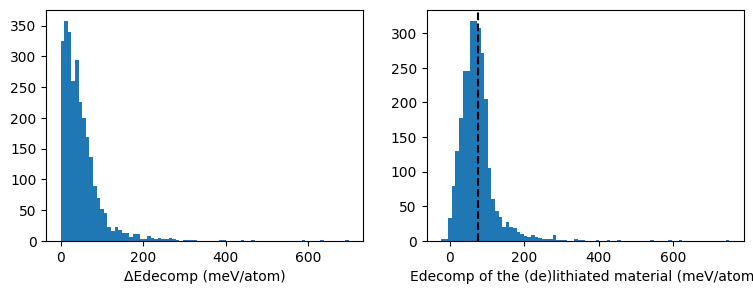

In [4]:
t = ds.transitions
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(1000 * t.delta_Edecomp.clip(-200, 600), bins=80); ax[0].set_xlabel("ΔEdecomp (meV/atom)")
ax[1].hist(1000 * t.Edecomp_final.clip(-200, 600), bins=80); ax[1].axvline(75, color="k", ls="--")
ax[1].set_xlabel("Edecomp of the (de)lithiated material (meV/atom)")
print(f"{(t.Edecomp_final > 0.075).mean():.0%} of (de)lithiated materials are more than 75 meV/atom above the hull")

## 2. Grouped split

The (de)lithiated materials of one electrode share its framework and are near-copies of each other. A random row
split puts siblings on both sides and overstates accuracy. So 10% of the **electrodes** are held out as the test set,
and the other 90% are split into 5 cross-validation folds by electrode. The split was fixed before any target was
looked at; `grouped_split` refuses any column besides the id and the group:

In [5]:
b = ds.battery_split
print(b.is_test.value_counts().rename({False: "train", True: "test"}).to_string())
print(b[~b.is_test].cv_fold.value_counts().sort_index().to_string())

is_test
train    2011
test      227
cv_fold
0    410
1    399
2    402
3    396
4    404


In [6]:
# What a random row split would report instead (for illustration only; same model, same folds count)
from sklearn.model_selection import KFold, cross_val_predict
from ion_insertion_modeling.model_building.train import make_estimator
rows = ds.train()
X, y = rows[list(FEATURE_SETS["interpretable5"])], rows.delta_Edecomp
pred_random = cross_val_predict(make_estimator("rf", min_samples_leaf=1, max_features=0.33), X, y,
                                cv=KFold(5, shuffle=True, random_state=0))
print(f"random row split MAE: {1000 * np.mean(np.abs(pred_random - y)):.1f} meV/atom")

random row split MAE: 25.1 meV/atom


With only five coarse features the random split looks about as good as the grouped CV below (≈25 meV/atom). The
difference grows with richer, more material-specific features, which let a model recognise a sibling it has seen.
The grouped split is used throughout so the numbers hold for frameworks the model has never seen.

## 3. Feature selection inside each fold

Candidate features: the 364 columns of the paper's reference set (Magpie statistics of the compositions, ion content,
P1-state properties, P1 scores, framework structure and insertion sites; all computable from the initial structure
and the two compositions). Within each fold's training rows only:
- a random forest pre-screens the top 40 by impurity importance;
- permutation importance on a grouped inner hold-out ranks them;
- a model with k features uses the top k.

The ranking on all training electrodes:

In [7]:
cols = list(FEATURE_SETS["reference"])
rows = ds.train()
ranking = rank_features(rows[cols], rows.delta_Edecomp.to_numpy(), rows.battery_id.to_numpy())
pd.Series(ranking[:15], name="feature").to_frame()

,feature
0,delta_p1_score
1,delta_li_frac
2,abs_delta_li_frac
3,mag_final_mean_Row
4,sites_per_fu
5,mag_final_mean_MeltingT
6,mag_initial_mean_NsValence
7,p1_score_initial
8,p1_score_final
9,site_vpv_mean


The interpretable five come from walking down a ranking made with `has_polyanion` forced into every
scoring model (`interpretable_ranking`):
- start from `has_polyanion`;
- skip a feature that is redundant with one already kept (normalised mutual information > 0.5);
- swap or drop a feature that mostly separates polyanion from non-polyanion frameworks (AUC > 0.7).

In [8]:
walk_ranking = interpretable_ranking(rows[cols], rows.delta_Edecomp.to_numpy(), rows.battery_id.to_numpy())
five, walk = interpretable_walk(walk_ranking, rows[cols], k=5)
print(five)
pd.DataFrame(walk).head(12)

['has_polyanion', 'delta_p1_score', 'delta_li_frac', 'mag_initial_mean_NsValence', 'radius_max_delta']


,feature,auc,outcome
0,delta_p1_score,0.559339,kept
1,delta_li_frac,0.503840,kept
2,abs_delta_li_frac,0.611178,redundant with delta_li_frac (NMI 0.61)
3,mag_final_mean_Row,0.850606,"confounded, dropped"
4,mag_final_mean_MeltingT,0.826029,"confounded, dropped"
5,p1_score_initial,0.789552,"confounded, dropped"
6,mag_initial_mean_NsValence,0.628403,kept
7,p1_score_final,0.723128,"confounded, dropped"
8,sites_per_fu,0.776262,"confounded, dropped"
9,poly_vol_ratio,0.872268,"confounded, dropped"


The paper's models keep the five frozen from an earlier version of the walk
(`has_polyanion, delta_p1_score, nval_d_redox_initial, delta_li_frac, site_cn_mean`). The rerun on the final
training set agrees on three and picks `mag_initial_mean_NsValence` and `radius_max_delta` for the last two slots;
the CV difference is within fold noise.

## 4. Cross-validation

`cross_validate` runs the 5 grouped folds. Per fold it ranks, tunes (inner grouped CV over `min_samples_leaf` and
`max_features`) and fits on that fold's training electrodes only, then predicts the held-out fold. Predictions become
Edecomp of the (de)lithiated material: Ê = Edecomp(initial) + ΔÊ.
- **Regression:** MAE in meV/atom.
- **Classification:** macro F1 of the call Ê > 75 meV/atom.
- **Capacity:** MAE of the stable-range capacity of each electrode (mAh/g).

In [9]:
cv5 = cross_validate(ds, "delta_edecomp", "interpretable5", ("all",))
display(cv5.summary()[["n_features", "mae_meV_mean", "mae_meV_std", "f1_macro_mean", "f1_macro_std"]].round(3))
cv5.capacity_summary(ds)[["cap_mae_mAhg_mean", "cap_mae_mAhg_std"]].round(1)

,n_features,mae_meV_mean,mae_meV_std,f1_macro_mean,f1_macro_std
0,all,25.207,1.286,0.734,0.023


,cap_mae_mAhg_mean,cap_mae_mAhg_std
0,34.7,3.0


The full reference set with fold-internal selection of k features (a few minutes):

In [10]:
QUICK = bool(os.environ.get("IIM_QUICK"))  # CI: two folds only
cvk = cross_validate(ds, "delta_edecomp", "reference", (3, 5, 10), folds=range(2) if QUICK else None)
cvk.summary()[["n_features", "mae_meV_mean", "mae_meV_std", "f1_macro_mean"]].round(3)

,n_features,mae_meV_mean,mae_meV_std,f1_macro_mean
0,3,25.715,1.190,0.719
1,5,24.864,1.321,0.736
2,10,23.722,1.371,0.747


### Parity plots

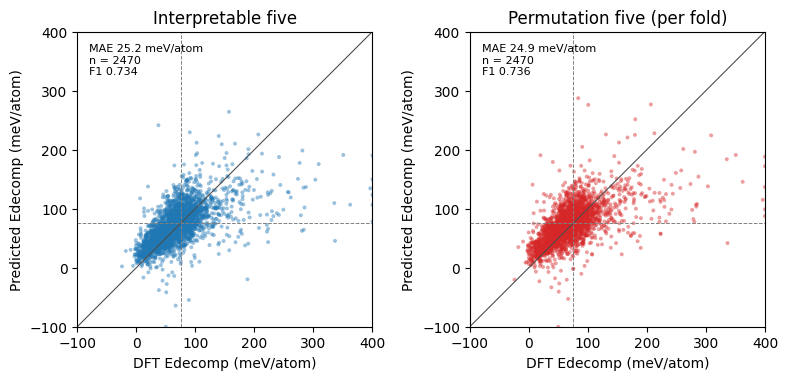

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
parity_from_cv(cv5, "all", ax=axes[0], color="tab:blue"); axes[0].set_title("Interpretable five")
parity_from_cv(cvk, 5, ax=axes[1], color="tab:red"); axes[1].set_title("Permutation five (per fold)")
plt.tight_layout()

The dashed lines are the 75 meV/atom cutoff, so the four quadrants are the stable/unstable confusion matrix. Most
errors are large Edecomp values predicted too low: very unstable (de)lithiated phases are rare, and the forest
cannot extrapolate past what it saw.

## 5. Other targets

The same call fits the other targets. Formation energy (`"eform"`) is converted to Edecomp with the hull of
the other phases. Edecomp itself (`"edecomp"`) can be trained on every material or only on the (de)lithiated ones:

In [12]:
cv_direct = cross_validate(ds, "edecomp", "interpretable5", ("all",), trained_on="final")
cv_direct.summary()[["mae_meV_mean", "f1_macro_mean"]].round(3)

,mae_meV_mean,f1_macro_mean
0,25.507,0.712


## 6. Final model

In [13]:
model = fit_final(ds, "delta_edecomp", "interpretable5")
print(model)
path = model.save("output/interpretable5_delta_Li")
print("saved", path)

TrainedModel(features=['has_polyanion', 'delta_p1_score', 'nval_d_redox_initial', 'delta_li_frac', 'site_cn_mean'], target='delta_edecomp', trained_on='final', ion='Li', params={'min_samples_leaf': 1, 'max_features': 0.33}, threshold=0.075, n_train_rows=2470, includes_test=False, data_fingerprint='c8ad2d646947b979', versions={'ion_insertion_modeling': '0.1.0', 'scikit-learn': '1.7.2', 'pymatgen': '2025.10.7', 'numpy': '2.2.6'})


saved output/interpretable5_delta_Li.skops
